In [3]:
import torch
import os
import matplotlib.pyplot as plt

from pathlib import Path

from src.data_loader import load_synthetic_fire_data
from src.evaluation.diversity import evaluate_semantic_similarity

In [5]:
# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

Working directory is already: C:\Users\Matej\Documents\GitHub\MasterThesis


In [6]:
synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_650_samples_4_examples.json"
#synthetic_data_path = Path("data") / "03_synthetic" / "few_shot_100_examples.json"
synthetic_data = load_synthetic_fire_data(synthetic_data_path)

sentences = [sample.sentence for sample in synthetic_data]

scores = evaluate_semantic_similarity(sentences)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 785.89it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Average Pairwise Similarity: 0.249

Most similar non identical sentences:
Pair 1 - Score: 0.979, idx1: 230, idx2: 560
  A: Apple is a subsidiary of no other company but has several subsidiaries including Beats Electronics and Claris.
  B: Apple is a subsidiary of no company but has subsidiaries like Beats Electronics and Claris

Pair 2 - Score: 0.979, idx1: 265, idx2: 474
  A: Amazon Web Services is a Subsidiaryof Amazon.com, Inc.
  B: Amazon Web Services is a subsidiary of Amazon.

Pair 3 - Score: 0.979, idx1: 229, idx2: 488
  A: The value of the asset is $100 million.
  B: The value of the asset is 100 million dollars.

Pair 4 - Score: 0.978, idx1: 122, idx2: 143
  A: The value of the stock increased by 10% in the first quarter.
  B: The value of the stock increased by 10% in the first quarter of the year.

Pair 5 - Score: 0.977, idx1: 352, idx2: 413
  A: ABC Inc. has a subsidiary, DEF Ltd., which is Locatedin New York, USA.
  B: ABC Inc. is a Subsidiaryof DEF Corp., and is Locatedin

In [7]:
scores.fill_diagonal_(-1)   # So it doesn't match with itself
max_scores, _ = torch.max(scores, dim=1)
max_scores_list = max_scores.tolist()

In [8]:
duplicates = sum(1 for score in max_scores_list if score >= 0.98)
very_similar = sum(1 for score in max_scores_list if 0.85 <= score < 0.98)
different = sum(1 for score in max_scores_list if score < 0.85)

print(f"Total Sentences: {len(sentences)}")
print(f"Exact/Near Duplicates (Score > 0.98): {duplicates} sentences")
print(f"Very Similar Sentences (Score 0.85-0.98): {very_similar} sentences")
print(f"Different Sentences (Score < 0.85): {different} sentences")

Total Sentences: 650
Exact/Near Duplicates (Score > 0.98): 93 sentences
Very Similar Sentences (Score 0.85-0.98): 231 sentences
Different Sentences (Score < 0.85): 326 sentences


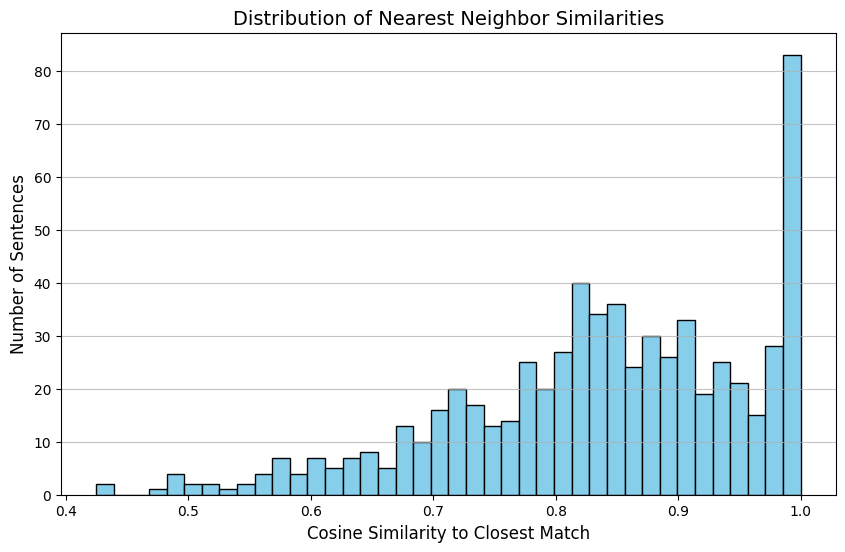

In [11]:
plt.figure(figsize=(10, 6))
plt.hist(max_scores_list, bins=40, color='skyblue', edgecolor='black')

plt.title("Distribution of Nearest Neighbor Similarities", fontsize=14)
plt.xlabel("Cosine Similarity to Closest Match", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.grid(axis='y', alpha=0.75)

plt.show()